In [1]:
import cv2
from google.colab.patches import cv2_imshow
import numpy as np
import matplotlib.pyplot as plt
from google.colab import drive
drive.mount('/content/gdrive')

Mounted at /content/gdrive


In [32]:
def threshold_update(img, binimg, T):
  sum1 = 0
  sum2 = 0
  count1 = 1
  count2 = 1

  for i in range(img.shape[0]):
    for j in range(img.shape[0]):
      if binimg[i][j] == 0:
        sum1 += img[i][j]
        count1 += 1
      else :
        sum2 += img[i][j]
        count2 += 1

  avg1 = sum1 / count1
  avg2 = sum2 / count2

  T2 = np.int32(avg1 + avg2)/2

  return T2

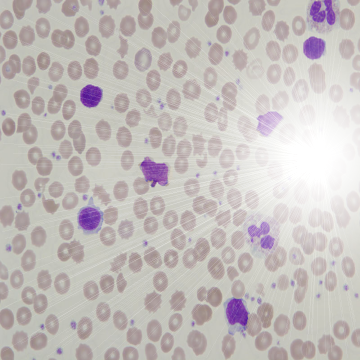

In [40]:
img = cv2.imread('/content/gdrive/My Drive/Colab26/Images/cell-bright.bmp')
RGB_img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

gray_img = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
gBin = np.zeros((RGB_img.shape[0], RGB_img.shape[1]), np.uint8)
cv2_imshow(img)

In [41]:
T1 = 128
T2 = 0
binimg = np.zeros(gray_img.shape, dtype=np.uint8)

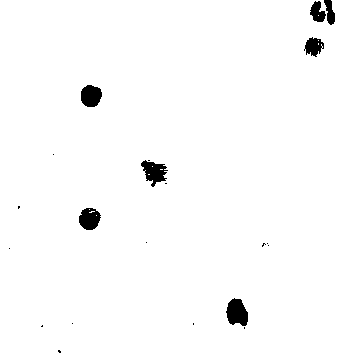

In [42]:
for i in range(gray_img.shape[0]):
  for j in range(gray_img.shape[0]):
    if gray_img[i][j] > T1:
      binimg[i][j] = 255
    else :
      binimg[i][j] = 0
cv2_imshow(binimg)

In [43]:
while True :
  T2 = threshold_update(gray_img, binimg, T1)

  if(np.abs(T1-T2) < 1):
    for i in range(gray_img.shape[0]):
     for j in range(gray_img.shape[0]):
      if gray_img[i][j] > T2:
        binimg[i][j] = 255
      else :
        binimg[i][j] = 0
    break
  else :
    T1 = T2
    for i in range(gray_img.shape[0]):
     for j in range(gray_img.shape[0]):
      if gray_img[i][j] > T1:
        binimg[i][j] = 255
      else :
        binimg[i][j] = 0

/tmp/ipykernel_562/2440121861.py:13: RuntimeWarning: overflow encountered in scalar add
  sum2 += img[i][j]
/tmp/ipykernel_562/2440121861.py:10: RuntimeWarning: overflow encountered in scalar add
  sum1 += img[i][j]


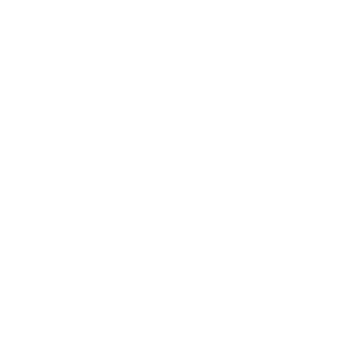

In [51]:
cv2_imshow(binimg)


183.0


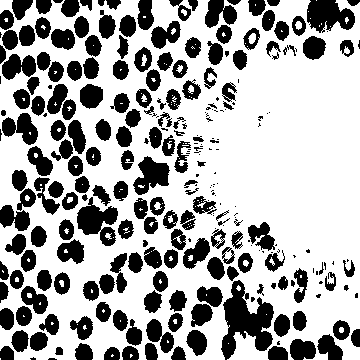

In [49]:
t, otsu = cv2.threshold(gray_img, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
print(t)
cv2_imshow(otsu)